## 0. Instalasi & import library

In [1]:
!pip install -q -U transformers accelerate

In [2]:
import os
import re
import copy
import json
import random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from IPython.display import display

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pd.set_option("display.max_colwidth", 100)
print("PyTorch", torch.__version__, "| device:", DEVICE)
if DEVICE.type == "cpu":
    print("PERINGATAN: GPU tidak aktif. Aktifkan lewat Runtime > Change runtime type > T4 GPU.")

PyTorch 2.14.1+cu130 | device: cuda


# 1. Eksplorasi Data

### 1.1 Load data dari Google Drive

In [3]:
from google.colab import drive
drive.mount("/content/drive/")

# >>> SESUAIKAN dengan lokasi folder dataset di Google Drive kamu <<<
DATA_DIR = "/content/drive/MyDrive/Colab Notebooks"

# Alternatif tanpa Drive: unggah 3 file CSV langsung ke Colab, lalu pakai DATA_DIR = "/content"
#   from google.colab import files; files.upload()

KOLOM = ["Konteks", "Pertanyaan", "Jawaban"]
train_df = pd.read_csv(f"{DATA_DIR}/train.csv", encoding="utf-8-sig")[KOLOM]
val_df   = pd.read_csv(f"{DATA_DIR}/valid.csv", encoding="utf-8-sig")[KOLOM]
test_df  = pd.read_csv(f"{DATA_DIR}/test.csv",  encoding="utf-8-sig")[KOLOM]

# buang baris kosong (file CSV berisi baris tanpa isi di bagian bawah)
print("Sebelum buang baris kosong:", len(train_df), len(val_df), len(test_df))
train_df = train_df.dropna(subset=["Pertanyaan", "Jawaban"]).reset_index(drop=True)
val_df   = val_df.dropna(subset=["Pertanyaan", "Jawaban"]).reset_index(drop=True)
test_df  = test_df.dropna(subset=["Pertanyaan", "Jawaban"]).reset_index(drop=True)
print("Sesudah buang baris kosong :", len(train_df), len(val_df), len(test_df))

for df in (train_df, val_df, test_df):
    for k in KOLOM:
        df[k] = df[k].fillna("").astype(str).str.strip()

train_df.head()

Mounted at /content/drive/
Sebelum buang baris kosong: 1698 1098 1198
Sesudah buang baris kosong : 1050 150 300


,Konteks,Pertanyaan,Jawaban
0,"Dalam lontar usadha Taru Pramana, kayu santen tercatat sebagai tanaman obat tradisional yang ber...",Apa khasiat kayu santen menurut lontar Usadha Taru Pramana?,Kayu santen berkhasiat untuk meredakan sakit maag.
1,"Dalam lontar usadha Taru Pramana, kayu santen tercatat sebagai tanaman obat tradisional yang ber...",Penyakit apa yang bisa diredakan dengan kayu santen?,Kayu santen berkhasiat untuk meredakan sakit maag.
2,"Dalam lontar usadha Taru Pramana, kayu santen tercatat sebagai tanaman obat tradisional yang ber...",Kayu santen berkhasiat untuk apa dalam lontar Taru Pramana?,Kayu santen berkhasiat untuk meredakan sakit maag.
3,"Dalam lontar usadha Taru Pramana, kayu santen tercatat sebagai tanaman obat tradisional yang ber...",Apa fungsi kayu santen sebagai tanaman obat Bali?,Kayu santen berkhasiat untuk meredakan sakit maag.
4,"Dalam lontar usadha Taru Pramana, kayu santen tercatat sebagai tanaman obat tradisional yang ber...",Manfaat kayu santen sebagai obat tradisional apa?,Kayu santen berkhasiat untuk meredakan sakit maag.


### 1.2 Jumlah data train, validation, dan test

,Split,Jumlah baris,Persentase,Jawaban unik
0,Train,1050,70%,150
1,Validation,150,10%,150
2,Test,300,20%,150
3,Total,1500,100%,150


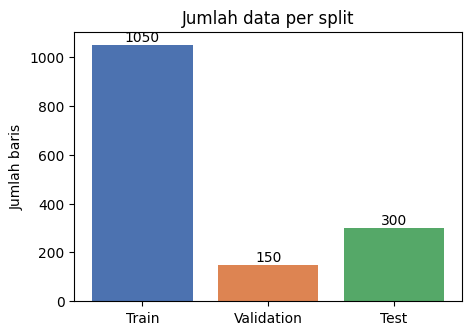

In [4]:
total = len(train_df) + len(val_df) + len(test_df)
ringkasan = pd.DataFrame({
    "Split": ["Train", "Validation", "Test", "Total"],
    "Jumlah baris": [len(train_df), len(val_df), len(test_df), total],
    "Persentase": [f"{len(d)/total:.0%}" for d in (train_df, val_df, test_df)] + ["100%"],
    "Jawaban unik": [d["Jawaban"].nunique() for d in (train_df, val_df, test_df)]
                    + [pd.concat([train_df, val_df, test_df])["Jawaban"].nunique()],
})
display(ringkasan)

plt.figure(figsize=(5, 3.5))
bar = plt.bar(ringkasan["Split"][:3], ringkasan["Jumlah baris"][:3], color=["#4C72B0", "#DD8452", "#55A868"])
plt.bar_label(bar)
plt.title("Jumlah data per split"); plt.ylabel("Jumlah baris"); plt.show()

### 1.3 Cek missing value, duplikat, dan kebocoran data

In [5]:
semua = pd.concat([train_df, val_df, test_df])
print("Missing value:\n", semua.replace("", np.nan).isna().sum(), "\n")

norm = lambda s: s.str.lower().str.strip()
print("Pertanyaan duplikat (seluruh split):", norm(semua["Pertanyaan"]).duplicated().sum())

# setiap jawaban di val/test harus ada di train, karena model hanya bisa memilih kelas yang pernah dipelajari
print("Semua jawaban val ada di train :", set(val_df.Jawaban) <= set(train_df.Jawaban))
print("Semua jawaban test ada di train:", set(test_df.Jawaban) <= set(train_df.Jawaban))

# kalimat pertanyaan val/test tidak boleh sama persis dengan train
q_train = set(norm(train_df["Pertanyaan"]))
print("Pertanyaan val yang sama dengan train :", norm(val_df["Pertanyaan"]).isin(q_train).sum())
print("Pertanyaan test yang sama dengan train:", norm(test_df["Pertanyaan"]).isin(q_train).sum())

Missing value:
 Konteks       0
Pertanyaan    0
Jawaban       0
dtype: int64 

Pertanyaan duplikat (seluruh split): 0
Semua jawaban val ada di train : True
Semua jawaban test ada di train: True
Pertanyaan val yang sama dengan train : 0
Pertanyaan test yang sama dengan train: 0


### 1.4 Kata yang paling sering muncul pada pertanyaan

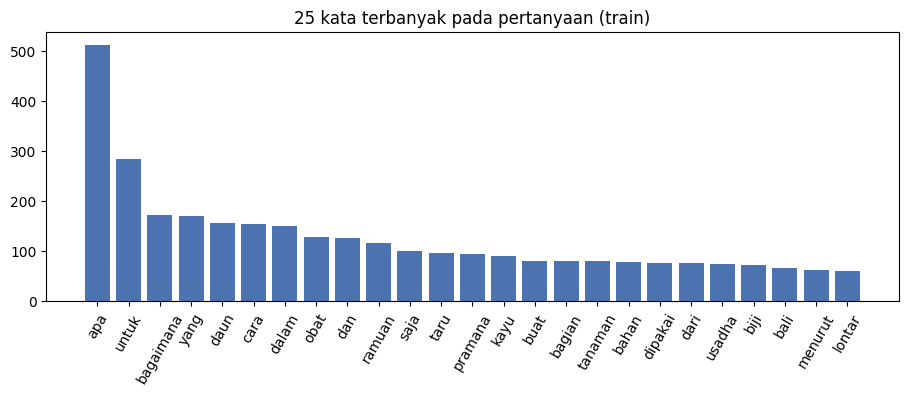

Jumlah kata unik pertanyaan train: 882


In [6]:
kata = Counter(w for q in train_df["Pertanyaan"].str.lower() for w in re.findall(r"[a-z]+", q))
top = pd.DataFrame(kata.most_common(25), columns=["kata", "frekuensi"])

plt.figure(figsize=(11, 3.5))
plt.bar(top["kata"], top["frekuensi"], color="#4C72B0")
plt.xticks(rotation=60); plt.title("25 kata terbanyak pada pertanyaan (train)"); plt.show()
print("Jumlah kata unik pertanyaan train:", len(kata))

# 2. Preprocessing

Pada notebook LSTM ada tahap *stopword removal*, *stemming*, pembuatan vocabulary manual, konversi ke angka, dan padding. Untuk RoBERTa, tahap-tahap itu **tidak dipakai**:

- RoBERTa dilatih pada kalimat utuh, sehingga membuang stopword dan men-stem kata justru menghilangkan konteks yang dipakai model.
- Tokenisasi, vocabulary, konversi ke ID, dan padding ditangani oleh tokenizer bawaan RoBERTa (subword BPE).

Tahap yang dipertahankan: case folding, cleaning, dan normalisasi kata tidak baku.

### Preprocessing 1: Case folding

In [7]:
def case_folding(text):
    return text.lower()

for df in (train_df, val_df, test_df):
    df["q"] = df["Pertanyaan"].apply(case_folding)

train_df[["Pertanyaan", "q"]].head(3)

,Pertanyaan,q
0,Apa khasiat kayu santen menurut lontar Usadha Taru Pramana?,apa khasiat kayu santen menurut lontar usadha taru pramana?
1,Penyakit apa yang bisa diredakan dengan kayu santen?,penyakit apa yang bisa diredakan dengan kayu santen?
2,Kayu santen berkhasiat untuk apa dalam lontar Taru Pramana?,kayu santen berkhasiat untuk apa dalam lontar taru pramana?


### Preprocessing 2: Cleaning

In [8]:
def cleaning(text):
    text = re.sub(r"[-–—/]", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

for df in (train_df, val_df, test_df):
    df["q"] = df["q"].apply(cleaning)

train_df[["Pertanyaan", "q"]].head(3)

,Pertanyaan,q
0,Apa khasiat kayu santen menurut lontar Usadha Taru Pramana?,apa khasiat kayu santen menurut lontar usadha taru pramana
1,Penyakit apa yang bisa diredakan dengan kayu santen?,penyakit apa yang bisa diredakan dengan kayu santen
2,Kayu santen berkhasiat untuk apa dalam lontar Taru Pramana?,kayu santen berkhasiat untuk apa dalam lontar taru pramana


### Preprocessing 3: Normalisasi kata tidak baku

In [9]:
kamus_normalisasi = {
    "gmn": "bagaimana", "gimana": "bagaimana", "gmana": "bagaimana",
    "bikin": "membuat", "dibikin": "dibuat", "bikinnya": "membuatnya",
    "gak": "tidak", "ga": "tidak", "gk": "tidak", "nggak": "tidak", "tdk": "tidak",
    "aja": "saja", "yg": "yang", "dgn": "dengan", "utk": "untuk", "sama": "dan",
    "dipake": "dipakai", "pake": "pakai", "ngobatin": "mengobati", "ngambil": "mengambil",
    "ngejelasin": "menjelaskan", "disimpen": "disimpan", "dapet": "dapat",
    "kulkas": "lemari es", "mencret": "diare", "serai": "sereh",
}

def normalisasi(text):
    return " ".join(kamus_normalisasi.get(w, w) for w in text.split())

for df in (train_df, val_df, test_df):
    df["q"] = df["q"].apply(normalisasi)

contoh = train_df[train_df["Pertanyaan"].str.lower().str.contains(r"\b(?:gimana|bikin|aja|gak)\b")]
contoh[["Pertanyaan", "q"]].head()

,Pertanyaan,q
13,isi ajaran taru pramana soal tumbuhan obat apa aja,isi ajaran taru pramana soal tumbuhan obat apa saja
20,kayu santen bisa buat radang lambung gak,kayu santen bisa buat radang lambung tidak
32,cara bikin usadha kayu santen di rumah,cara membuat usadha kayu santen di rumah
75,cara pakai boreh kencur gimana,cara pakai boreh kencur bagaimana
101,minyak cem-ceman dipakai gimana buat rambut dan aromaterapi,minyak cem ceman dipakai bagaimana buat rambut dan aromaterapi


### Preprocessing 4: Tokenisasi RoBERTa

In [10]:
MODEL_NAME = "flax-community/indonesian-roberta-base"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

contoh_q = train_df["q"].iloc[0]
tok = tokenizer.tokenize(contoh_q)
print("Kalimat :", contoh_q)
print("Token   :", tok)
print("ID      :", tokenizer(contoh_q)["input_ids"])

config.json:   0%|          | 0.00/671 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/292 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/808k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/467k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.38M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Kalimat : apa khasiat kayu santen menurut lontar usadha taru pramana
Token   : ['apa', 'Ġkhasiat', 'Ġkayu', 'Ġsant', 'en', 'Ġmenurut', 'Ġlontar', 'Ġus', 'adha', 'Ġt', 'aru', 'Ġpr', 'amana']
ID      : [0, 422, 5954, 2832, 5215, 264, 1656, 45005, 2552, 32754, 276, 1077, 663, 12106, 2]


### Preprocessing 5: Menentukan panjang maksimum, lalu encoding + padding

In [11]:
panjang = [len(ids) for ids in tokenizer(train_df["q"].tolist())["input_ids"]]
MAX_LEN = min(max(panjang) + 2, 256)
print(f"Panjang token (train): min {min(panjang)} | rata-rata {np.mean(panjang):.1f} | maks {max(panjang)}")
print("MAX_LEN:", MAX_LEN)

def encode(texts):
    enc = tokenizer(texts, truncation=True, max_length=MAX_LEN, padding="max_length", return_tensors="pt")
    return enc["input_ids"], enc["attention_mask"]

ids_train, mask_train = encode(train_df["q"].tolist())
ids_val,   mask_val   = encode(val_df["q"].tolist())
ids_test,  mask_test  = encode(test_df["q"].tolist())
print("ids_train:", tuple(ids_train.shape), "| ids_val:", tuple(ids_val.shape), "| ids_test:", tuple(ids_test.shape))

Panjang token (train): min 6 | rata-rata 11.7 | maks 21
MAX_LEN: 23
ids_train: (1050, 23) | ids_val: (150, 23) | ids_test: (300, 23)


### Preprocessing 6: Label encoding

In [12]:
daftar_jawaban = list(dict.fromkeys(train_df["Jawaban"]))   # urutan kemunculan di train
jawaban2id = {j: i for i, j in enumerate(daftar_jawaban)}
id2jawaban = {i: j for j, i in jawaban2id.items()}
NUM_CLASSES = len(jawaban2id)

y_train = train_df["Jawaban"].map(jawaban2id).values
y_val   = val_df["Jawaban"].map(jawaban2id).values
y_test  = test_df["Jawaban"].map(jawaban2id).values
assert not (pd.isna(y_val).any() or pd.isna(y_test).any()), "Ada jawaban val/test yang tidak ada di train"

y_train_t = torch.tensor(y_train, dtype=torch.long)
y_val_t   = torch.tensor(y_val,   dtype=torch.long)
y_test_t  = torch.tensor(y_test,  dtype=torch.long)

print("Jumlah kelas:", NUM_CLASSES)
print("Contoh: kelas 0 →", id2jawaban[0][:80], "...")

Jumlah kelas: 150
Contoh: kelas 0 → Kayu santen berkhasiat untuk meredakan sakit maag. ...


# 3. Model RoBERTa

### Arsitektur dan teknik regularisasi

| Teknik | Nilai | Letak | Fungsi |
|---|---|---|---|
| **Encoder RoBERTa pre-trained** | 12 layer | seluruh encoder | representasi kalimat yang sudah dilatih pada korpus bahasa Indonesia, di-fine-tune pada data ini |
| **Classification head** | `num_labels` = jumlah jawaban | di atas token `<s>` | memetakan representasi kalimat ke kelas jawaban (softmax) |
| **Dropout hidden** | 0,1 | di dalam encoder | mematikan sebagian neuron secara acak saat training |
| **Dropout classifier** | 0,3 | classification head | mengurangi ketergantungan pada neuron tertentu |
| **Weight decay (AdamW)** | 0,01 | semua bobot kecuali bias & LayerNorm | penalti pada bobot besar (pengganti L2 pada notebook LSTM) |
| **Learning rate berbeda** | encoder 5e-5, head 1e-3 | optimizer | head dimulai dari acak sehingga perlu belajar lebih cepat |
| **Warmup + linear decay** | warmup 10% | scheduler | menghindari update besar di awal sehingga bobot pre-trained tidak rusak |
| **Gradient clipping** | 1,0 | tiap step | menjaga stabilitas training |
| **EarlyStopping** | patience 10 | proses training | menghentikan training saat `val_loss` tidak membaik, lalu mengembalikan bobot ke epoch terbaik |

In [13]:
CONFIG = dict(
    model_name=MODEL_NAME,
    hidden_dropout=0.1,
    classifier_dropout=0.3,
    lr_encoder=5e-5,
    lr_head=1e-3,
    weight_decay=0.01,
    warmup_ratio=0.1,
    max_grad_norm=1.0,
)

model = AutoModelForSequenceClassification.from_pretrained(
    CONFIG["model_name"],
    num_labels=NUM_CLASSES,
    hidden_dropout_prob=CONFIG["hidden_dropout"],
    classifier_dropout=CONFIG["classifier_dropout"],
).to(DEVICE)

jumlah_param = sum(p.numel() for p in model.parameters())
print(f"Jumlah parameter: {jumlah_param/1e6:.1f} juta | jumlah kelas: {NUM_CLASSES}")

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: flax-community/indonesian-roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.bias               | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Jumlah parameter: 124.8 juta | jumlah kelas: 150


# 4. Training

In [14]:
EPOCHS = 100
BATCH_SIZE = 16
PATIENCE = 10
USE_AMP = DEVICE.type == "cuda"     # mixed precision agar lebih cepat di GPU

g = torch.Generator(); g.manual_seed(SEED)
train_loader = DataLoader(TensorDataset(ids_train, mask_train, y_train_t), batch_size=BATCH_SIZE, shuffle=True, generator=g)
val_loader   = DataLoader(TensorDataset(ids_val,   mask_val,   y_val_t),   batch_size=64)
test_loader  = DataLoader(TensorDataset(ids_test,  mask_test,  y_test_t),  batch_size=64)
# loader train tanpa shuffle, dipakai untuk menghitung ulang akurasi train tanpa dropout
train_eval_loader = DataLoader(TensorDataset(ids_train, mask_train, y_train_t), batch_size=64)

# optimizer: learning rate encoder vs head berbeda, weight decay tidak dikenakan pada bias & LayerNorm
no_decay = ["bias", "LayerNorm.weight"]
param_groups = []
for is_head in (False, True):
    for decay in (True, False):
        params = [p for n, p in model.named_parameters()
                  if n.startswith("classifier") == is_head and (not any(nd in n for nd in no_decay)) == decay]
        param_groups.append({
            "params": params,
            "lr": CONFIG["lr_head"] if is_head else CONFIG["lr_encoder"],
            "weight_decay": CONFIG["weight_decay"] if decay else 0.0,
        })
optimizer = torch.optim.AdamW(param_groups)

total_steps = len(train_loader) * EPOCHS
scheduler = get_linear_schedule_with_warmup(
    optimizer, int(CONFIG["warmup_ratio"] * total_steps), total_steps)
criterion = nn.CrossEntropyLoss()
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

def run_epoch(loader, train=False):
    model.train(train)
    total_loss, benar, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for ids, mask, y in loader:
            ids, mask, y = ids.to(DEVICE), mask.to(DEVICE), y.to(DEVICE)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                logits = model(input_ids=ids, attention_mask=mask).logits
            loss = criterion(logits.float(), y)
            if train:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                nn.utils.clip_grad_norm_(model.parameters(), CONFIG["max_grad_norm"])
                scaler.step(optimizer); scaler.update(); scheduler.step()
            total_loss += loss.item() * len(y)
            benar += (logits.argmax(dim=1) == y).sum().item()
            n += len(y)
    return total_loss / n, benar / n

history = {"loss": [], "val_loss": [], "accuracy": [], "val_accuracy": []}
best_val_loss, best_state, best_epoch, tanpa_perbaikan = float("inf"), None, 0, 0

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = run_epoch(train_loader, train=True)
    va_loss, va_acc = run_epoch(val_loader, train=False)
    for k, v in zip(history, (tr_loss, va_loss, tr_acc, va_acc)):
        history[k].append(v)
    print(f"Epoch {epoch:3d}/{EPOCHS} | loss {tr_loss:.4f} acc {tr_acc:.4f} | val_loss {va_loss:.4f} val_acc {va_acc:.4f}")

    if va_loss < best_val_loss:
        best_val_loss, best_epoch, tanpa_perbaikan = va_loss, epoch, 0
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    else:
        tanpa_perbaikan += 1
        if tanpa_perbaikan >= PATIENCE:
            print(f"Early stopping di epoch {epoch}. Bobot dikembalikan ke epoch terbaik ({best_epoch}).")
            break

model.load_state_dict(best_state)
model.to(DEVICE)

Epoch   1/100 | loss 5.0741 acc 0.0067 | val_loss 4.9520 val_acc 0.0133
Epoch   2/100 | loss 4.9298 acc 0.0210 | val_loss 4.6266 val_acc 0.1600
Epoch   3/100 | loss 4.3651 acc 0.2124 | val_loss 3.5174 val_acc 0.6467
Epoch   4/100 | loss 2.9734 acc 0.6248 | val_loss 1.6354 val_acc 0.8400
Epoch   5/100 | loss 1.2927 acc 0.8286 | val_loss 0.6289 val_acc 0.8600
Epoch   6/100 | loss 0.5060 acc 0.8981 | val_loss 0.2934 val_acc 0.9400
Epoch   7/100 | loss 0.2171 acc 0.9543 | val_loss 0.2111 val_acc 0.9467
Epoch   8/100 | loss 0.1023 acc 0.9743 | val_loss 0.1460 val_acc 0.9600
Epoch   9/100 | loss 0.0541 acc 0.9886 | val_loss 0.1254 val_acc 0.9667
Epoch  10/100 | loss 0.0191 acc 0.9952 | val_loss 0.1478 val_acc 0.9667
Epoch  11/100 | loss 0.0145 acc 0.9971 | val_loss 0.1202 val_acc 0.9667
Epoch  12/100 | loss 0.0033 acc 1.0000 | val_loss 0.0712 val_acc 0.9867
Epoch  13/100 | loss 0.0014 acc 1.0000 | val_loss 0.1379 val_acc 0.9800
Epoch  14/100 | loss 0.0007 acc 1.0000 | val_loss 0.1393 val_acc

RobertaForSequenceClassification(
  (roberta): RobertaModel(
    (embeddings): RobertaEmbeddings(
      (word_embeddings): Embedding(50265, 768, padding_idx=1)
      (token_type_embeddings): Embedding(1, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
      (position_embeddings): Embedding(514, 768, padding_idx=1)
    )
    (encoder): RobertaEncoder(
      (layer): ModuleList(
        (0-11): 12 x RobertaLayer(
          (attention): RobertaAttention(
            (self): RobertaSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): RobertaSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
  

### Grafik loss & akurasi

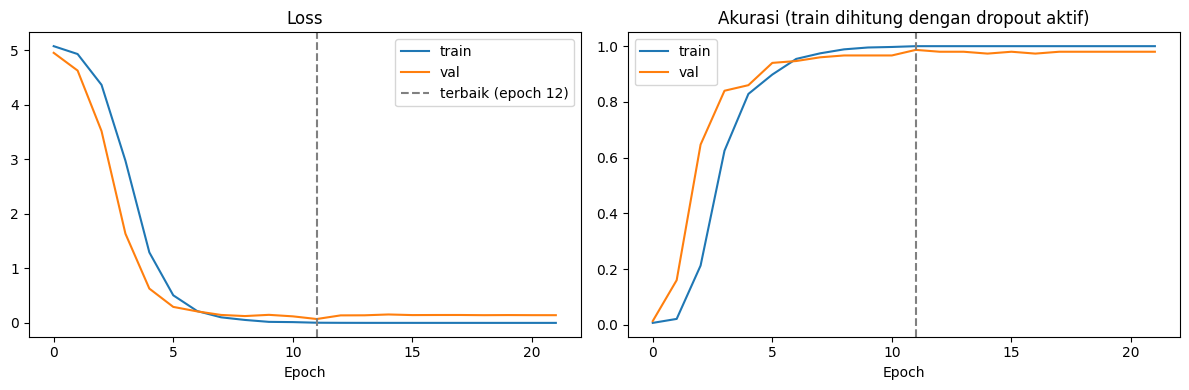

Epoch terbaik: 12 | val_loss: 0.0712
Akurasi train: 0.9990 | val: 0.9867 | selisih (indikasi overfitting): 0.0124
Total epoch dijalankan: 22


In [15]:
h = history
terbaik = int(np.argmin(h["val_loss"]))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h["loss"], label="train"); ax[0].plot(h["val_loss"], label="val")
ax[0].axvline(terbaik, ls="--", c="gray", label=f"terbaik (epoch {terbaik+1})")
ax[0].set_title("Loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(h["accuracy"], label="train"); ax[1].plot(h["val_accuracy"], label="val")
ax[1].axvline(terbaik, ls="--", c="gray")
ax[1].set_title("Akurasi (train dihitung dengan dropout aktif)"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout(); plt.show()
print(f"Epoch terbaik: {terbaik+1} | val_loss: {h['val_loss'][terbaik]:.4f}")

# akurasi dihitung ulang tanpa dropout (dropout hanya aktif saat training,
# sehingga akurasi train di grafik terlihat lebih rendah dari sebenarnya)
acc_train = run_epoch(train_eval_loader, train=False)[1]
acc_val   = run_epoch(val_loader, train=False)[1]
print(f"Akurasi train: {acc_train:.4f} | val: {acc_val:.4f} | selisih (indikasi overfitting): {acc_train - acc_val:.4f}")
print(f"Total epoch dijalankan: {len(h['loss'])}")

# 5. Evaluasi

### Metrik pada data test

In [16]:
@torch.no_grad()
def predict_proba(loader):
    model.eval()
    semua_prob = []
    for ids, mask, _ in loader:
        logits = model(input_ids=ids.to(DEVICE), attention_mask=mask.to(DEVICE)).logits
        semua_prob.append(torch.softmax(logits.float(), dim=1).cpu().numpy())
    return np.concatenate(semua_prob)

def evaluasi(loader, y):
    prob = predict_proba(loader)
    pred = prob.argmax(axis=1)
    p, r, f1, _ = precision_recall_fscore_support(y, pred, average="macro", zero_division=0)
    return {
        "Accuracy": accuracy_score(y, pred),
        "Precision (macro)": p, "Recall (macro)": r, "F1 (macro)": f1,
    }, prob, pred

skor_test, prob_test, pred_test = evaluasi(test_loader, y_test)
display(pd.DataFrame([skor_test], index=["Test"]).round(4))

,Accuracy,Precision (macro),Recall (macro),F1 (macro)
Test,0.9633,0.9633,0.9633,0.9578


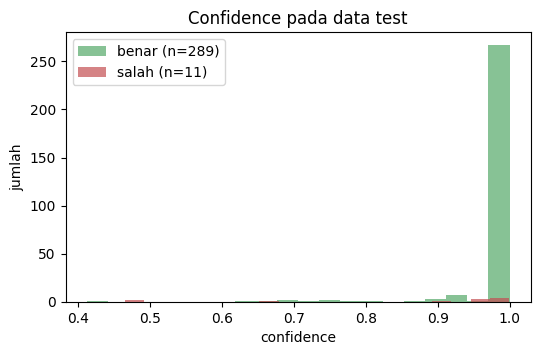

Rata-rata confidence benar: 0.984 | salah: 0.851


In [17]:
conf = prob_test.max(axis=1)
benar = pred_test == y_test
plt.figure(figsize=(6, 3.5))
plt.hist(conf[benar], bins=20, alpha=0.7, label=f"benar (n={benar.sum()})", color="#55A868")
plt.hist(conf[~benar], bins=20, alpha=0.7, label=f"salah (n={(~benar).sum()})", color="#C44E52")
plt.xlabel("confidence"); plt.ylabel("jumlah"); plt.legend(); plt.title("Confidence pada data test")
plt.show()
print(f"Rata-rata confidence benar: {conf[benar].mean():.3f} | salah: {conf[~benar].mean() if (~benar).any() else float('nan'):.3f}")

# 6. Uji coba chatbot

In [18]:
@torch.no_grad()
def tanya(pertanyaan, top_k=1):
    q = normalisasi(cleaning(case_folding(pertanyaan)))
    enc = tokenizer(q, truncation=True, max_length=MAX_LEN, padding="max_length", return_tensors="pt").to(DEVICE)
    model.eval()
    prob = torch.softmax(model(**enc).logits.float(), dim=1)[0].cpu().numpy()
    for i in prob.argsort()[::-1][:top_k]:
        print(f"[confidence {prob[i]:.3f}] {id2jawaban[i]}\n")

tanya(test_df["Pertanyaan"].iloc[0])
print("Jawaban sebenarnya:", test_df["Jawaban"].iloc[0])

[confidence 0.898] Kayu santen berkhasiat untuk meredakan sakit maag.

Jawaban sebenarnya: Kayu santen berkhasiat untuk meredakan sakit maag.


# 7. Menyimpan Model

In [19]:
SAVE_DIR = "/content/drive/MyDrive/Chatbot Usada/model_roberta"
os.makedirs(SAVE_DIR, exist_ok=True)
model.save_pretrained(SAVE_DIR)
tokenizer.save_pretrained(SAVE_DIR)
with open(f"{SAVE_DIR}/id2jawaban.json", "w", encoding="utf-8") as f:
    json.dump({str(k): v for k, v in id2jawaban.items()}, f, ensure_ascii=False)
with open(f"{SAVE_DIR}/config_preprocessing.json", "w", encoding="utf-8") as f:
    json.dump({"max_len": MAX_LEN, "kamus_normalisasi": kamus_normalisasi}, f, ensure_ascii=False)
print("Model tersimpan di:", SAVE_DIR)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model tersimpan di: /content/drive/MyDrive/Chatbot Usada/model_roberta
